In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import re
from datetime import datetime

In [86]:
df_voter = pd.read_csv('null_dropped_data.csv')

# Reformat the .md file to df 
with open('datasets_question/gender-filled-dataset.md', 'r') as file:
    data = file.read()

# Can you split and reformat the data so that these are the column names: "LALVOTERID,Voters_FirstName,Voters_Gender

# Split the data by the new line character
data_split = data.split('\n')
data_split = data_split[1:]

# Split the data by the comma character
data_split = [x.split(',') for x in data_split]

# Create a new dataframe with the data
df_gender_filled = pd.DataFrame(data_split, columns=['LALVOTERID', 'Voters_FirstName', 'Voters_Gender'])

# df_gender_filled

gender_map = df_gender_filled.set_index('LALVOTERID')['Voters_Gender'].to_dict()

# Fill in the missing Voters_Gender values in df_voter using the mapping
df_voter['Voters_Gender'] = df_voter['LALVOTERID'].map(gender_map).combine_first(df_voter['Voters_Gender'])

C:\Users\91704\AppData\Local\Temp/ipykernel_6092/3122284348.py:1: DtypeWarning: Columns (11,22,23,27,29,38,44,45,49,51,67,72,160,161,162,163,164,165,166,168,169,170,171,172,173,174,177,178,181,183,186,193,194,196,205,213,225,231,232,243,259,266,268,488,489,510,515) have mixed types. Specify dtype option on import or set low_memory=False.
  df_voter = pd.read_csv('null_dropped_data.csv')


In [87]:
# fill in null precinct values acc to knn

from sklearn.neighbors import NearestNeighbors

# Separate rows with known and unknown precincts
df_known = df_voter[df_voter['Precinct'].notnull()].copy()
df_unknown = df_voter[df_voter['Precinct'].isnull()].copy()

# Drop rows in the known subset with missing coordinates
df_known = df_known.dropna(subset=['Residence_Addresses_Latitude', 'Residence_Addresses_Longitude'])

# Extract the latitude and longitude values from the cleaned known precinct DataFrame
X_known = df_known[['Residence_Addresses_Latitude', 'Residence_Addresses_Longitude']].values

# Also drop any rows in the unknown subset that are missing coordinates, if any
df_unknown = df_unknown.dropna(subset=['Residence_Addresses_Latitude', 'Residence_Addresses_Longitude'])
X_unknown = df_unknown[['Residence_Addresses_Latitude', 'Residence_Addresses_Longitude']].values

# Initialize and fit the NearestNeighbors model with 1 neighbor
nn_model = NearestNeighbors(n_neighbors=1, metric='euclidean')
nn_model.fit(X_known)

# Find the nearest neighbor for each unknown
distances, indices = nn_model.kneighbors(X_unknown)

# Assign the precinct from the nearest neighbor to the unknown rows
assigned_precincts = df_known.iloc[indices.flatten()]['Precinct'].values
df_unknown['Precinct'] = assigned_precincts

# Merge the dataframes back together
df_voter = pd.concat([df_known, df_unknown], ignore_index=True)


In [88]:
local_municipal_elec_dates = ['2023-11-07', '2023-09-19', '2023-05-16', '2023-03-28', '2021-11-02', '2021-09-14', '2019-11-05', '2019-09-17', '2017-11-07', '2017-09-12', '2015-11-03', '2015-09-29', '2013-11-05', '2013-09-24', '2013-09-17']

# Convert election dates to datetime objects
election_dates = pd.to_datetime(local_municipal_elec_dates)

# Function to calculate age on a specific date
def calculate_age(birth_date, on_date):
    """Calculate age of a person on a specific date"""
    birth_date = pd.to_datetime(birth_date)
    age = on_date.year - birth_date.year - ((on_date.month, on_date.day) < (birth_date.month, birth_date.day))
    return age

# Create a dictionary to store ages for each election
voter_ages = {}

# Calculate ages for each election date
for election_date in election_dates:
    election_str = election_date.strftime('%Y-%m-%d')
    voter_ages[election_str] = df_voter['Voters_BirthDate'].apply(lambda x: calculate_age(x, election_date))

# Create a DataFrame with voter ages for each election
voter_ages_df = pd.DataFrame(voter_ages)

# Add the VoterID column from the original dataframe
voter_ages_df['LALVOTERID'] = df_voter['LALVOTERID']  # Assuming 'VoterID' is the column name

# Set VoterID as the index to make it a unique identifier
voter_ages_df.set_index('LALVOTERID', inplace=True)

# Preview the results
voter_ages_df.head()


,2023-11-07,2023-09-19,2023-05-16,2023-03-28,2021-11-02,2021-09-14,2019-11-05,2019-09-17,2017-11-07,2017-09-12,2015-11-03,2015-09-29,2013-11-05,2013-09-24,2013-09-17
LALVOTERID,,,,,,,,,,,,,,,
LALMA461833413,29.0,29.0,29.0,29.0,27.0,27.0,25.0,25.0,23.0,23.0,21.0,21.0,19.0,19.0,19.0
LALMA604158873,27.0,27.0,26.0,26.0,25.0,25.0,23.0,23.0,21.0,21.0,19.0,19.0,17.0,17.0,17.0
LALMA410465965,30.0,30.0,29.0,29.0,28.0,28.0,26.0,26.0,24.0,24.0,22.0,22.0,20.0,20.0,20.0
LALMA162405966,76.0,76.0,76.0,76.0,74.0,74.0,72.0,72.0,70.0,70.0,68.0,68.0,66.0,66.0,66.0
LALMA442082670,72.0,72.0,72.0,72.0,70.0,70.0,68.0,68.0,66.0,66.0,64.0,64.0,62.0,62.0,62.0


In [89]:
import pandas as pd
import numpy as np
import re

# Convert dates to datetime format
df_voter['Voters_BirthDate'] = pd.to_datetime(df_voter['Voters_BirthDate'])
df_voter['Voters_OfficialRegDate'] = pd.to_datetime(df_voter['Voters_OfficialRegDate'])

# Find all election columns using updated regex (excluding BallotType_ and PRI_BLT_ columns)
election_columns = {}
pattern = r'^(?!BallotType_)(?!PRI_BLT_)(.*?)_(\d{4}-\d{2}-\d{2})$'

for col in df_voter.columns:
    match = re.match(pattern, col)
    if match:
        election_type = match.group(1)  # Type (Local_or_Municipal, General, etc.)
        election_date = match.group(2)  # Date
        election_columns[col] = {
            'type': election_type,
            'date': election_date,
            'datetime': pd.to_datetime(election_date)
        }

# Sort election columns by date
sorted_election_columns = sorted(
    election_columns.items(), 
    key=lambda x: x[1]['datetime']
)

# Create a DataFrame with VoterIDs
result_df = pd.DataFrame({'VoterID': df_voter['LALVOTERID']})

# Process each election column
for column_name, info in sorted_election_columns:
    election_type = info['type']
    election_date = info['date']
    election_datetime = info['datetime']
    
    # Create result column name
    result_column_name = f"{election_type}_{election_date}"
    
    # Calculate eligibility and voting status
    eligibility_status = []
    
    for _, voter in df_voter.iterrows():
        # Eligibility based only on registration date
        eligible = voter['Voters_OfficialRegDate'] <= election_datetime
        
        # Determine if they voted
        voted = not pd.isna(voter[column_name])
        
        # Create status label
        if eligible and voted:
            status = "Eligible_Voted"
        elif eligible and not voted:
            status = "Eligible_Did_Not_Vote"
        elif not eligible and voted:
            status = "Ineligible_Voted"
        else:
            status = "Ineligible_Did_Not_Vote"
            
        eligibility_status.append(status)
    
    # Add the column to the result DataFrame
    result_df[result_column_name] = eligibility_status

# Add election type column for each election
for column_name, info in sorted_election_columns:
    election_type = info['type']
    election_date = info['date']
    result_df[f"Type_{election_date}"] = election_type

print(f"Found {len(election_columns)} election columns (excluding BallotType_ and PRI_BLT_ columns)")
print("\nResult dataframe sample (including election types):")
print(result_df.head())

# Calculate participation rates for each election
participation_rates = {}

for column_name, info in sorted_election_columns:
    election_type = info['type']
    election_date = info['date']
    result_column = f"{election_type}_{election_date}"
    
    # Count eligible voters who voted
    eligible_voted = (result_df[result_column] == "Eligible_Voted").sum()
    
    # Count total eligible voters
    total_eligible = ((result_df[result_column] == "Eligible_Voted") | 
                      (result_df[result_column] == "Eligible_Did_Not_Vote")).sum()
    
    # Calculate participation rate
    if total_eligible > 0:
        participation_rate = eligible_voted / total_eligible
    else:
        participation_rate = 0
    
    participation_rates[election_date] = {
        'ElectionType': election_type,
        'EligibleVoted': eligible_voted,
        'TotalEligible': total_eligible,
        'ParticipationRate': participation_rate,
        'ParticipationPercentage': f"{participation_rate * 100:.2f}%"
    }

# Create summary dataframe for participation rates
participation_df = pd.DataFrame.from_dict(participation_rates, orient='index')
participation_df.sort_index(inplace=True)

print("\nElection participation rates:")
print(participation_df.head())

Found 31 election columns (excluding BallotType_ and PRI_BLT_ columns)

Result dataframe sample (including election types):
          VoterID       Special_2013-04-30       Special_2013-06-25  \
0  LALMA461833413  Ineligible_Did_Not_Vote  Ineligible_Did_Not_Vote   
1  LALMA604158873  Ineligible_Did_Not_Vote  Ineligible_Did_Not_Vote   
2  LALMA410465965  Ineligible_Did_Not_Vote  Ineligible_Did_Not_Vote   
3  LALMA162405966    Eligible_Did_Not_Vote    Eligible_Did_Not_Vote   
4  LALMA442082670  Ineligible_Did_Not_Vote  Ineligible_Did_Not_Vote   

  Local_or_Municipal_2013-09-17 Local_or_Municipal_2013-09-24  \
0       Ineligible_Did_Not_Vote       Ineligible_Did_Not_Vote   
1       Ineligible_Did_Not_Vote       Ineligible_Did_Not_Vote   
2       Ineligible_Did_Not_Vote       Ineligible_Did_Not_Vote   
3                Eligible_Voted         Eligible_Did_Not_Vote   
4         Eligible_Did_Not_Vote         Eligible_Did_Not_Vote   

  Local_or_Municipal_2013-11-05       Special_2013-11-05  

In [90]:
participation_df

,ElectionType,EligibleVoted,TotalEligible,ParticipationRate,ParticipationPercentage
2013-04-30,Special,2274,11416,0.199194,19.92%
2013-06-25,Special,3695,11487,0.321668,32.17%
2013-09-17,Local_or_Municipal,2242,11603,0.193226,19.32%
2013-09-24,Local_or_Municipal,3,11618,0.000258,0.03%
2013-11-05,Special,4405,11698,0.376560,37.66%
2014-09-09,Primary,3418,12178,0.280670,28.07%
2014-11-04,General,7874,12398,0.635102,63.51%
2015-09-29,Local_or_Municipal,645,12950,0.049807,4.98%
2015-11-03,Local_or_Municipal,4397,13084,0.336059,33.61%
2016-03-01,Presidential_Primary,7498,13763,0.544794,54.48%


In [91]:
# Create a long format dataframe with one row per voter-election combination
voter_election_rows = []

for column_name, info in sorted_election_columns:
    election_type = info['type']
    election_date = info['date']
    election_datetime = info['datetime']
    result_column_name = f"{election_type}_{election_date}"
    
    for index, voter in df_voter.iterrows():
        voter_id = voter['LALVOTERID']
        
        # Eligibility based only on registration date
        eligible = voter['Voters_OfficialRegDate'] <= election_datetime
        
        # Determine if they voted
        voted = not pd.isna(voter[column_name])
        
        # Create status label
        if eligible and voted:
            status = "Eligible_Voted"
        elif eligible and not voted:
            status = "Eligible_Did_Not_Vote"
        elif not eligible and voted:
            status = "Ineligible_Voted"
        else:
            status = "Ineligible_Did_Not_Vote"
        
        # Add row to results
        voter_election_rows.append({
            'VoterID': voter_id,
            'ElectionDate': election_date,
            'ElectionType': election_type,
            'EligibilityStatus': status,
            'Eligible': eligible,
            'Voted': voted
        })

# Create the long format dataframe
long_format_df = pd.DataFrame(voter_election_rows)

# Calculate participation rates for each election
participation_by_election = long_format_df.groupby(['ElectionDate', 'ElectionType']).agg(
    EligibleVoted=('EligibilityStatus', lambda x: (x == 'Eligible_Voted').sum()),
    TotalEligible=('Eligible', 'sum')
).reset_index()

participation_by_election['TurnoutRate'] = participation_by_election['EligibleVoted'] / participation_by_election['TotalEligible']
participation_by_election['TurnoutPercentage'] = participation_by_election['TurnoutRate'].apply(lambda x: f"{x*100:.2f}%")

# Keep only the columns needed for the merge
election_turnout = participation_by_election[['ElectionDate', 'ElectionType', 'TurnoutRate', 'TurnoutPercentage']]

# Merge the turnout rates back into the long format dataframe
long_format_df = long_format_df.merge(election_turnout, on=['ElectionDate', 'ElectionType'])

# Display the first few rows of the enhanced dataframe
print("Long format dataframe with turnout rates:")
print(long_format_df.head(10))

# Verify that all voters for the same election have the same turnout rate
sample_election = long_format_df['ElectionDate'].iloc[0]
sample_type = long_format_df['ElectionType'].iloc[0]
sample_turnout = long_format_df[(long_format_df['ElectionDate'] == sample_election) & 
                               (long_format_df['ElectionType'] == sample_type)]['TurnoutRate'].nunique()

print(f"\nNumber of unique turnout rates for {sample_type}_{sample_election}: {sample_turnout} (should be 1)")

Long format dataframe with turnout rates:
          VoterID ElectionDate ElectionType        EligibilityStatus  \
0  LALMA461833413   2013-04-30      Special  Ineligible_Did_Not_Vote   
1  LALMA604158873   2013-04-30      Special  Ineligible_Did_Not_Vote   
2  LALMA410465965   2013-04-30      Special  Ineligible_Did_Not_Vote   
3  LALMA162405966   2013-04-30      Special    Eligible_Did_Not_Vote   
4  LALMA442082670   2013-04-30      Special  Ineligible_Did_Not_Vote   
5  LALMA162456843   2013-04-30      Special           Eligible_Voted   
6  LALMA162666076   2013-04-30      Special    Eligible_Did_Not_Vote   
7  LALMA161400044   2013-04-30      Special         Ineligible_Voted   
8  LALMA538506266   2013-04-30      Special  Ineligible_Did_Not_Vote   
9  LALMA518046457   2013-04-30      Special  Ineligible_Did_Not_Vote   

   Eligible  Voted  TurnoutRate TurnoutPercentage  
0     False  False     0.199194            19.92%  
1     False  False     0.199194            19.92%  
2     Fal

In [92]:
# Create a mapping of voter ID to birth date
voter_birthdate_map = df_voter.set_index('LALVOTERID')['Voters_BirthDate'].to_dict()

# Create a mapping of voter ID to registration date
voter_regdate_map = df_voter.set_index('LALVOTERID')['Voters_OfficialRegDate'].to_dict()

# Add birth dates and registration dates temporarily using the mapping
long_format_df['temp_birthdate'] = long_format_df['VoterID'].map(voter_birthdate_map)
long_format_df['temp_regdate'] = long_format_df['VoterID'].map(voter_regdate_map)

# Convert election dates to datetime
long_format_df['temp_election_date'] = pd.to_datetime(long_format_df['ElectionDate'])

# Calculate ages using vectorized operations
long_format_df['Age_at_Election'] = (
    long_format_df['temp_election_date'].dt.year - 
    long_format_df['temp_birthdate'].dt.year - 
    ((long_format_df['temp_election_date'].dt.month < long_format_df['temp_birthdate'].dt.month) | 
     ((long_format_df['temp_election_date'].dt.month == long_format_df['temp_birthdate'].dt.month) & 
      (long_format_df['temp_election_date'].dt.day < long_format_df['temp_birthdate'].dt.day)))
)

# Calculate both eligibility criteria
long_format_df['Age_Eligible'] = long_format_df['Age_at_Election'] >= 18
long_format_df['Registration_Eligible'] = long_format_df['temp_regdate'] <= long_format_df['temp_election_date']

# Create the new combined eligibility column
long_format_df['Eligible'] = long_format_df['Age_Eligible'] & long_format_df['Registration_Eligible']

# Update the eligibility status based on new criteria
conditions = [
    (long_format_df['Eligible'] == True) & (long_format_df['Voted'] == True),
    (long_format_df['Eligible'] == True) & (long_format_df['Voted'] == False),
    (long_format_df['Eligible'] == False) & (long_format_df['Voted'] == True),
    (long_format_df['Eligible'] == False) & (long_format_df['Voted'] == False)
]
choices = ['Eligible_Voted', 'Eligible_Did_Not_Vote', 'Ineligible_Voted', 'Ineligible_Did_Not_Vote']
long_format_df['EligibilityStatus'] = np.select(conditions, choices)

# Remove temporary columns
long_format_df.drop(['temp_birthdate', 'temp_election_date', 'temp_regdate'], axis=1, inplace=True)

# Recalculate participation rates for each election with updated eligibility
updated_participation = long_format_df.groupby(['ElectionDate', 'ElectionType']).agg(
    EligibleVoted=('EligibilityStatus', lambda x: (x == 'Eligible_Voted').sum()),
    TotalEligible=('Eligible', 'sum')
).reset_index()

updated_participation['TurnoutRate'] = updated_participation['EligibleVoted'] / updated_participation['TotalEligible']
updated_participation['TurnoutPercentage'] = updated_participation['TurnoutRate'].apply(lambda x: f"{x*100:.2f}%")

# Remove old turnout columns if they exist
if 'TurnoutRate' in long_format_df.columns:
    long_format_df = long_format_df.drop(['TurnoutRate', 'TurnoutPercentage'], axis=1, errors='ignore')

# Merge the updated turnout rates back into long_format_df
long_format_df = long_format_df.merge(
    updated_participation[['ElectionDate', 'ElectionType', 'TurnoutRate', 'TurnoutPercentage']], 
    on=['ElectionDate', 'ElectionType']
)

updated_participation

# # Display updated turnout rates
# print("Updated turnout rates by election (including 18+ age requirement):")
# election_summary = updated_participation.sort_values('ElectionDate', ascending=False)
# print(election_summary[['ElectionDate', 'ElectionType', 'EligibleVoted', 'TotalEligible', 'TurnoutRate', 'TurnoutPercentage']].head(10))

# # Show stats for ineligible voters who voted
# ineligible_voted = long_format_df[long_format_df['EligibilityStatus'] == 'Ineligible_Voted']
# print(f"\nNumber of instances where ineligible voters cast votes: {len(ineligible_voted)}")
# print(f"Due to age: {len(ineligible_voted[~ineligible_voted['Age_Eligible']])}")
# print(f"Due to registration: {len(ineligible_voted[~ineligible_voted['Registration_Eligible']])}")

# # Display final dataframe structure
# print("\nFinal dataframe structure:")
# print(long_format_df.columns.tolist())
# print(f"Total records: {len(long_format_df)}")

,ElectionDate,ElectionType,EligibleVoted,TotalEligible,TurnoutRate,TurnoutPercentage
0,2013-04-30,Special,2271,11393,0.199333,19.93%
1,2013-06-25,Special,3691,11461,0.322049,32.20%
2,2013-09-17,Local_or_Municipal,2239,11580,0.193351,19.34%
3,2013-09-24,Local_or_Municipal,3,11596,0.000259,0.03%
4,2013-11-05,Local_or_Municipal,4198,11676,0.359541,35.95%
5,2013-11-05,Special,4399,11676,0.376756,37.68%
6,2014-09-09,Primary,3415,12156,0.280931,28.09%
7,2014-11-04,General,7868,12376,0.635747,63.57%
8,2015-09-29,Local_or_Municipal,645,12926,0.049899,4.99%
9,2015-11-03,Local_or_Municipal,4394,13061,0.336421,33.64%


In [93]:
long_format_df

,VoterID,ElectionDate,ElectionType,EligibilityStatus,Eligible,Voted,Age_at_Election,Age_Eligible,Registration_Eligible,TurnoutRate,TurnoutPercentage
0,LALMA461833413,2013-04-30,Special,Ineligible_Did_Not_Vote,False,False,19.0,True,False,0.199333,19.93%
1,LALMA604158873,2013-04-30,Special,Ineligible_Did_Not_Vote,False,False,16.0,False,False,0.199333,19.93%
2,LALMA410465965,2013-04-30,Special,Ineligible_Did_Not_Vote,False,False,19.0,True,False,0.199333,19.93%
3,LALMA162405966,2013-04-30,Special,Eligible_Did_Not_Vote,True,False,66.0,True,True,0.199333,19.93%
4,LALMA442082670,2013-04-30,Special,Ineligible_Did_Not_Vote,False,False,62.0,True,False,0.199333,19.93%
...,...,...,...,...,...,...,...,...,...,...,...
994413,LALMA410155097,2024-03-05,Presidential_Primary,Eligible_Did_Not_Vote,True,False,71.0,True,True,0.228624,22.86%
994414,LALMA159543975,2024-03-05,Presidential_Primary,Eligible_Did_Not_Vote,True,False,65.0,True,True,0.228624,22.86%
994415,LALMA410395894,2024-03-05,Presidential_Primary,Eligible_Did_Not_Vote,True,False,35.0,True,True,0.228624,22.86%
994416,LALMA160899592,2024-03-05,Presidential_Primary,Eligible_Did_Not_Vote,True,False,40.0,True,True,0.228624,22.86%


In [94]:
voter_party_dict = df_voter.set_index('LALVOTERID')['Parties_Description'].to_dict()
long_format_df['ElectionDate'] = pd.to_datetime(long_format_df['ElectionDate'])
long_format_df['Voter_Enrollment'] = long_format_df['VoterID'].map(voter_party_dict)
long_format_df['Year'] = long_format_df['ElectionDate'].dt.year
updated_participation_party = long_format_df.groupby(['Year', 'ElectionType', 'Voter_Enrollment']).agg(
    EligibleVoted=('EligibilityStatus', lambda x: (x == 'Eligible_Voted').sum()),
    TotalEligible=('Eligible', 'sum'),
    # Democrat=('Voter_Enrollment', lambda x: (x == 'Democratic').sum()),
    # Republican=('Voter_Enrollment', lambda x: (x == 'Republican').sum()),
    # Unenrolled=('Voter_Enrollment', lambda x: (x == 'Non-Partisan').sum())
).reset_index()
updated_participation_party['TurnoutRate'] = updated_participation_party['EligibleVoted'] / updated_participation_party['TotalEligible']
updated_participation_party['TurnoutPercentage'] = updated_participation_party['TurnoutRate'].apply(lambda x: f"{x*100:.2f}%")

updated_participation_party[updated_participation_party['Voter_Enrollment'].isin(['Democratic', 'Republican','Non-Partisan']) & (updated_participation_party['Year'].isin(range(2015,2023,1))) & (updated_participation_party['ElectionType'] == 'Local_or_Municipal')]

,Year,ElectionType,Voter_Enrollment,EligibleVoted,TotalEligible,TurnoutRate,TurnoutPercentage
46,2015,Local_or_Municipal,Democratic,2109,9672,0.218052,21.81%
49,2015,Local_or_Municipal,Non-Partisan,2666,14417,0.184921,18.49%
52,2015,Local_or_Municipal,Republican,250,1670,0.149701,14.97%
90,2017,Local_or_Municipal,Democratic,4911,12139,0.404564,40.46%
93,2017,Local_or_Municipal,Non-Partisan,6146,17946,0.342472,34.25%
96,2017,Local_or_Municipal,Republican,651,2114,0.307947,30.79%
123,2019,Local_or_Municipal,Democratic,4589,14459,0.317380,31.74%
126,2019,Local_or_Municipal,Non-Partisan,5663,21460,0.263886,26.39%
129,2019,Local_or_Municipal,Republican,517,2494,0.207298,20.73%
167,2021,Local_or_Municipal,Democratic,6751,17683,0.381779,38.18%


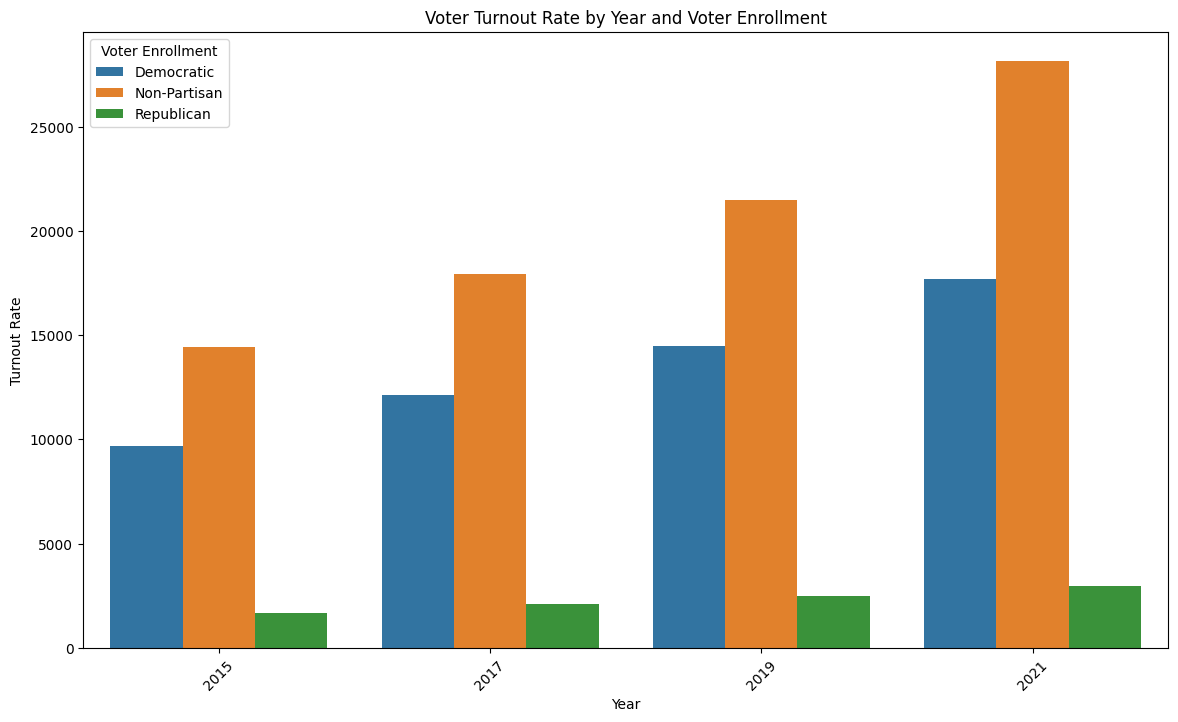

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter the data for the required voter enrollments and years
filtered_data = updated_participation_party[
    updated_participation_party['Voter_Enrollment'].isin(['Democratic', 'Republican', 'Non-Partisan']) & 
    (updated_participation_party['Year'].isin(range(2015, 2023))) & 
    (updated_participation_party['ElectionType'] == 'Local_or_Municipal')
]

# Set the figure size
plt.figure(figsize=(14, 8))

# Create the bar plot
sns.barplot(
    data=filtered_data, 
    x='Year', 
    y='TotalEligible', 
    hue='Voter_Enrollment'
)

# Set the title and labels
plt.title('Voter Turnout Rate by Year and Voter Enrollment')
plt.xlabel('Year')
plt.ylabel('Turnout Rate')
plt.xticks(rotation=45)
plt.legend(title='Voter Enrollment')

# Show the plot
plt.show()

<Axes: xlabel='TurnoutRate', ylabel='TotalEligible'>

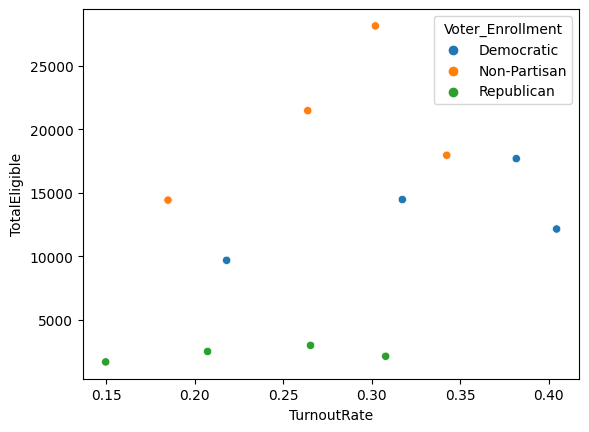

In [96]:
sns.scatterplot(filtered_data, x='TurnoutRate', y='TotalEligible', hue='Voter_Enrollment')


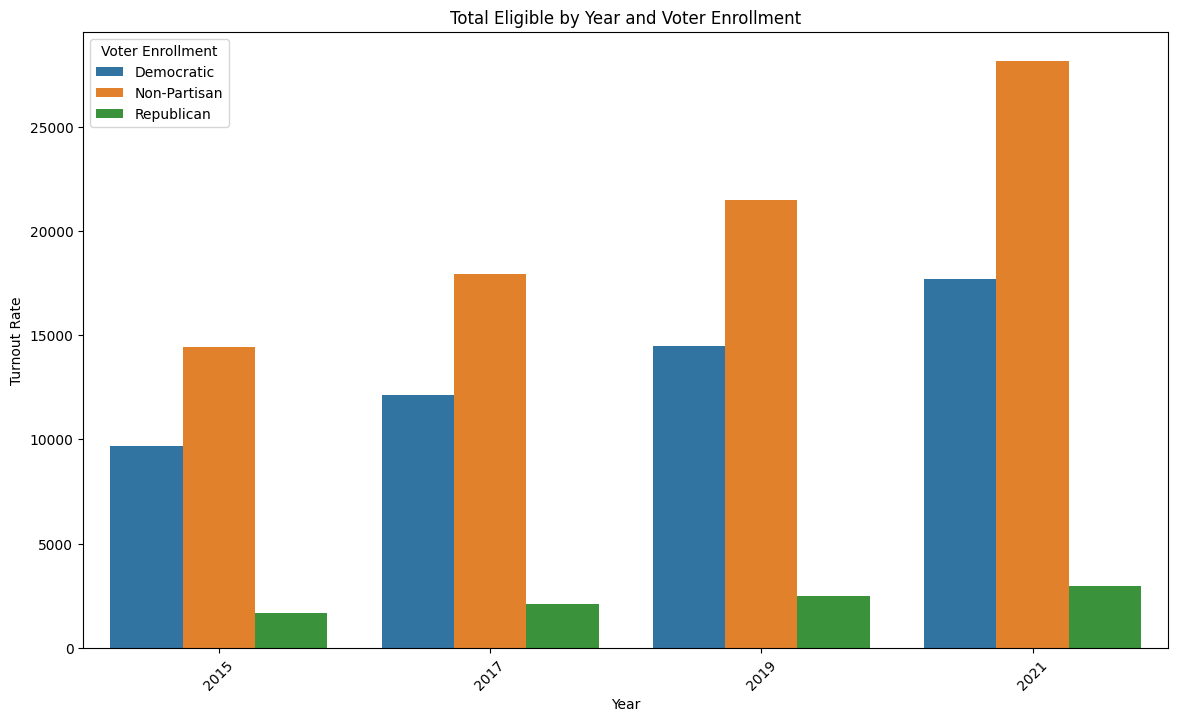

In [97]:
plt.figure(figsize=(14, 8))

# Create the bar plot
sns.barplot(
    data=filtered_data, 
    x='Year', 
    y='TotalEligible', 
    hue='Voter_Enrollment'
)

# Set the title and labels
plt.title('Total Eligible by Year and Voter Enrollment')
plt.xlabel('Year')
plt.ylabel('Turnout Rate')
plt.xticks(rotation=45)
plt.legend(title='Voter Enrollment')

# Show the plot
plt.show()

In [98]:
midterm_dates = ['2018-11-06', '2022-11-08']
# Convert ElectionDate to datetime if it's not already
updated_participation['ElectionDate'] = pd.to_datetime(updated_participation['ElectionDate'])

# First update the ElectionType column for midterm dates
updated_participation['ElectionType'] = updated_participation.apply(
    lambda row: "Midterm" if row['ElectionDate'].strftime('%Y-%m-%d') in midterm_dates else row['ElectionType'], 
    axis=1
)

# Create the new SpecElectionType column
def categorize_election(row):
    if row['ElectionType'] == 'Local_or_Municipal':
        return 'Municipal'
    else:
        return 'Federal'

updated_participation['SpecElectionType'] = updated_participation.apply(categorize_election, axis=1)
filtered_participation = updated_participation[
    (updated_participation['ElectionDate'].dt.year >= 2015) & 
    (updated_participation['ElectionDate'].dt.year <= 2022)
]

filtered_participation['Year'] = filtered_participation['ElectionDate'].dt.year

# Group by Year and SpecElectionType and aggregate
yearly_participation = filtered_participation.groupby(['Year', 'SpecElectionType']).agg(
    Total_Elections=('ElectionDate', 'count'),
    Total_Eligible=('TotalEligible', 'sum'),
    Total_Voted=('EligibleVoted', 'sum')
).reset_index()

# Calculate the aggregated turnout rate for each year/type
yearly_participation['TurnoutRate'] = yearly_participation['Total_Voted'] / yearly_participation['Total_Eligible']
yearly_participation['TurnoutPercentage'] = (yearly_participation['TurnoutRate'] * 100).round(2)

# Sort by year (descending) and election type
yearly_participation = yearly_participation.sort_values(['Year', 'SpecElectionType'], ascending=[True, True])

# Display the results
print("Yearly participation rates by election type (2015-2022):")
yearly_participation

Yearly participation rates by election type (2015-2022):


C:\Users\91704\AppData\Local\Temp/ipykernel_6092/270327620.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_participation['Year'] = filtered_participation['ElectionDate'].dt.year


,Year,SpecElectionType,Total_Elections,Total_Eligible,Total_Voted,TurnoutRate,TurnoutPercentage
0,2015,Municipal,2,25987,5039,0.193905,19.39
1,2016,Federal,3,43571,22179,0.509031,50.90
2,2017,Municipal,2,32578,11771,0.361317,36.13
3,2018,Federal,2,35532,16686,0.469605,46.96
4,2019,Municipal,2,38922,10817,0.277915,27.79
5,2020,Federal,3,64988,37588,0.578384,57.84
6,2021,Municipal,2,49426,16158,0.326913,32.69
7,2022,Federal,2,54964,23622,0.429772,42.98


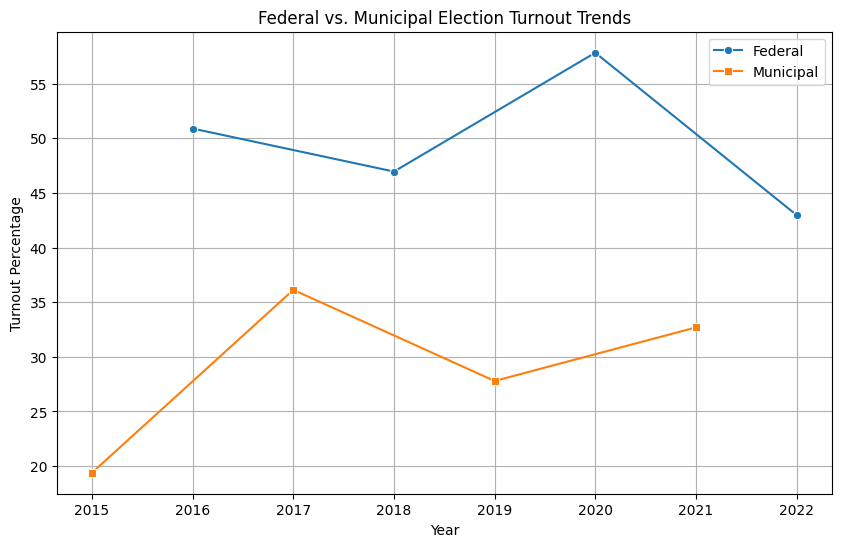

In [99]:
# yearly_participation = yearly_participation['Year'].sort_values(ascending=True)
df_federal = yearly_participation[yearly_participation["SpecElectionType"] == "Federal"]
df_municipal = yearly_participation[yearly_participation["SpecElectionType"] == "Municipal"]

# Plot
plt.figure(figsize=(10, 6))
sns.lineplot(x=df_federal["Year"], y=df_federal["TurnoutPercentage"], marker="o", label="Federal")
sns.lineplot(x=df_municipal["Year"], y=df_municipal["TurnoutPercentage"], marker="s", label="Municipal")

plt.xlabel("Year")
plt.ylabel("Turnout Percentage")
plt.title("Federal vs. Municipal Election Turnout Trends")
plt.legend()
plt.grid(True)
plt.show()

In [100]:
long_format_df

,VoterID,ElectionDate,ElectionType,EligibilityStatus,Eligible,Voted,Age_at_Election,Age_Eligible,Registration_Eligible,TurnoutRate,TurnoutPercentage,Voter_Enrollment,Year
0,LALMA461833413,2013-04-30,Special,Ineligible_Did_Not_Vote,False,False,19.0,True,False,0.199333,19.93%,Non-Partisan,2013
1,LALMA604158873,2013-04-30,Special,Ineligible_Did_Not_Vote,False,False,16.0,False,False,0.199333,19.93%,Non-Partisan,2013
2,LALMA410465965,2013-04-30,Special,Ineligible_Did_Not_Vote,False,False,19.0,True,False,0.199333,19.93%,Democratic,2013
3,LALMA162405966,2013-04-30,Special,Eligible_Did_Not_Vote,True,False,66.0,True,True,0.199333,19.93%,Non-Partisan,2013
4,LALMA442082670,2013-04-30,Special,Ineligible_Did_Not_Vote,False,False,62.0,True,False,0.199333,19.93%,Non-Partisan,2013
...,...,...,...,...,...,...,...,...,...,...,...,...,...
994413,LALMA410155097,2024-03-05,Presidential_Primary,Eligible_Did_Not_Vote,True,False,71.0,True,True,0.228624,22.86%,Democratic,2024
994414,LALMA159543975,2024-03-05,Presidential_Primary,Eligible_Did_Not_Vote,True,False,65.0,True,True,0.228624,22.86%,Republican,2024
994415,LALMA410395894,2024-03-05,Presidential_Primary,Eligible_Did_Not_Vote,True,False,35.0,True,True,0.228624,22.86%,Democratic,2024
994416,LALMA160899592,2024-03-05,Presidential_Primary,Eligible_Did_Not_Vote,True,False,40.0,True,True,0.228624,22.86%,Non-Partisan,2024


In [101]:
# Define age groups
def categorize_age(age):
    if age >= 75:
        return '75+'
    elif age >= 65:
        return '65-74'
    elif age >= 56:
        return '56-64'
    elif age >= 46:
        return '46-55'
    elif age >= 36:
        return '36-45'
    elif age >= 26:
        return '26-35'
    elif age >= 18:
        return '18-25'
    elif age < 18:
        return 'Under 18'  # Handling any edge cases
# Apply age categorization
    else:
        return 'Unkown Age'
# Add age group column
long_format_df['Age_Group'] = long_format_df['Age_at_Election'].apply(categorize_age)

# Calculate turnout by age group for each election
age_group_turnout = long_format_df.groupby(['ElectionDate', 'ElectionType', 'Age_Group']).agg(
    Voted_Count=('Voted', 'sum'),
    Eligible_Count=('Eligible', 'sum')
).reset_index()

# Calculate turnout percentage
age_group_turnout['Turnout_Rate'] = age_group_turnout['Voted_Count'] / age_group_turnout['Eligible_Count']
age_group_turnout['Turnout_Percentage'] = age_group_turnout['Turnout_Rate'].apply(lambda x: f"{x*100:.2f}%")

# Display turnout by age group
print("Turnout percentages by age group:")
print(age_group_turnout.sort_values(['ElectionDate', 'Age_Group']).head(20))

# Create a pivot table for easier visualization
age_turnout_pivot = age_group_turnout.pivot_table(
    index=['ElectionDate', 'ElectionType'],
    columns='Age_Group',
    values='Turnout_Rate'
)

# Display the pivot table with age groups as columns
print("\nTurnout rate pivot table (age groups as columns):")
print(age_turnout_pivot.head())

# Calculate average turnout by age group across all elections
avg_age_turnout = long_format_df.groupby('Age_Group').agg(
    Voted_Count=('Voted', 'sum'),
    Eligible_Count=('Eligible', 'sum')
)
avg_age_turnout['Avg_Turnout_Rate'] = avg_age_turnout['Voted_Count'] / avg_age_turnout['Eligible_Count']
avg_age_turnout['Avg_Turnout_Percentage'] = avg_age_turnout['Avg_Turnout_Rate'].apply(lambda x: f"{x*100:.2f}%")

# Sort by age group in a logical order
age_group_order = ['18-25', '26-35', '36-45', '46-55', '56-64', '65-74', '75+', 'Under 18']
avg_age_turnout = avg_age_turnout.reindex(age_group_order)

print("\nAverage turnout by age group across all elections:")
avg_age_turnout

Turnout percentages by age group:
   ElectionDate        ElectionType   Age_Group  Voted_Count  Eligible_Count  \
0    2013-04-30             Special       18-25          116             742   
1    2013-04-30             Special       26-35          223            1261   
2    2013-04-30             Special       36-45          375            2061   
3    2013-04-30             Special       46-55          657            2859   
4    2013-04-30             Special       56-64          839            2453   
5    2013-04-30             Special       65-74          655            1533   
6    2013-04-30             Special         75+          200             484   
7    2013-04-30             Special    Under 18            1               0   
8    2013-04-30             Special  Unkown Age            4               0   
9    2013-06-25             Special       18-25          293             746   
10   2013-06-25             Special       26-35          454            1266   
11   2

,Voted_Count,Eligible_Count,Avg_Turnout_Rate,Avg_Turnout_Percentage
Age_Group,,,,
18-25,14532,54047,0.268877,26.89%
26-35,33753,101683,0.331943,33.19%
36-45,33763,96036,0.351566,35.16%
46-55,41241,105043,0.392611,39.26%
56-64,45808,104533,0.438216,43.82%
65-74,44126,86431,0.510534,51.05%
75+,21664,43927,0.493182,49.32%
Under 18,4,0,inf,inf%


In [104]:
age_group_turnout['ElectionDate'] = pd.to_datetime(age_group_turnout['ElectionDate'])

age_group_turnout = age_group_turnout[
    (age_group_turnout['ElectionDate'].dt.year >= 2015) & 
    (age_group_turnout['ElectionDate'].dt.year <= 2022)
]

age_group_turnout['ElectionType'] = age_group_turnout.apply(
    lambda row: "Midterm" if row['ElectionDate'].strftime('%Y-%m-%d') in midterm_dates else row['ElectionType'], 
    axis=1
)

# Create the new SpecElectionType column
def categorize_election(row):
    if row['ElectionType'] == 'Local_or_Municipal':
        return 'Municipal'
    else:
        return 'Federal'

age_group_turnout['SpecElectionType'] = age_group_turnout.apply(categorize_election, axis=1)
age_group_turnout['Year'] = age_group_turnout['ElectionDate'].dt.year

# Aggregate data by Year, SpecElectionType and Age_Group
aggregated_age_turnout = age_group_turnout.groupby(['Year', 'SpecElectionType', 'Age_Group']).agg(
    Total_Voted=('Voted_Count', 'sum'),
    Total_Eligible=('Eligible_Count', 'sum')
).reset_index()

# Calculate new turnout rates based on the aggregated values
aggregated_age_turnout['Turnout_Rate'] = aggregated_age_turnout['Total_Voted'] / aggregated_age_turnout['Total_Eligible']
aggregated_age_turnout['Turnout_Percentage'] = aggregated_age_turnout['Turnout_Rate'].apply(lambda x: f"{x*100:.2f}%")

# Sort by year (recent first), type, and age group
aggregated_age_turnout = aggregated_age_turnout.sort_values(
    ['Year', 'SpecElectionType', 'Age_Group'], 
    ascending=[False, True, True]
)

# Display the aggregated data
print("Aggregated turnout by year, election type and age group:")
aggregated_age_turnout

# Create a pivot table for easier analysis
# Years as rows, age groups as columns, split by election type
age_year_pivot = aggregated_age_turnout.pivot_table(
    index=['Year', 'SpecElectionType'], 
    columns='Age_Group', 
    values='Turnout_Rate'
)

# Display the pivot table
print("\nPivot table of turnout rates by year, election type, and age group:")
age_year_pivot

Aggregated turnout by year, election type and age group:

Pivot table of turnout rates by year, election type, and age group:


,Age_Group,18-25,26-35,36-45,46-55,56-64,65-74,75+,Unkown Age
Year,SpecElectionType,,,,,,,,
2015,Municipal,0.128005,0.136744,0.182142,0.212419,0.240864,0.285643,0.307390,inf
2016,Federal,1.018309,0.922516,0.630063,0.626570,0.659150,0.664869,0.644903,inf
2017,Municipal,0.197487,0.299790,0.367189,0.403218,0.429723,0.486299,0.489786,inf
2018,Federal,0.591427,0.722202,0.547327,0.540189,0.575037,0.646637,0.633399,inf
2019,Municipal,0.093189,0.169973,0.279050,0.305803,0.344147,0.406000,0.433277,inf
2020,Federal,0.613181,0.759617,0.662469,0.632600,0.674682,0.745661,0.701997,inf
2021,Municipal,0.097465,0.207444,0.315877,0.362543,0.403685,0.510999,0.501615,inf
2022,Federal,0.188027,0.328985,0.401638,0.455346,0.522646,0.653253,0.636907,inf


In [105]:
# Calculate turnout by gender for each specific election (including date)
voter_gender_map = df_voter.set_index('LALVOTERID')['Voters_Gender'].to_dict()

# Add gender to long_format_df using the mapping (efficient vectorized operation)
long_format_df['Voters_Gender'] = long_format_df['VoterID'].map(voter_gender_map)

gender_by_specific_election = long_format_df.groupby(['ElectionDate', 'ElectionType', 'Voters_Gender'], dropna=False).agg(
    Voted_Count=('Voted', 'sum'),
    Eligible_Count=('Eligible', 'sum')
).reset_index()

gender_by_specific_election['Turnout_Rate'] = gender_by_specific_election['Voted_Count'] / gender_by_specific_election['Eligible_Count']
gender_by_specific_election['Turnout_Percentage'] = gender_by_specific_election['Turnout_Rate'].apply(lambda x: f"{x*100:.2f}%")

# Sort by date (most recent first) and then by gender
gender_by_specific_election = gender_by_specific_election.sort_values(['ElectionDate', 'ElectionType', 'Voters_Gender'], ascending=[False, True, True])

# Display the updated table including election dates
print("Turnout by gender for each specific election:")
print(gender_by_specific_election.head(15))

# If you want a more compact pivot table format with genders as columns
gender_election_pivot = gender_by_specific_election.pivot_table(
    index=['ElectionDate', 'ElectionType'],
    columns='Voters_Gender',
    values=['Turnout_Rate', 'Voted_Count', 'Eligible_Count'],
    dropna=False
).reset_index()

# Flatten the multi-level column names for easier use
gender_election_pivot.columns = ['_'.join(col).strip('_') for col in gender_election_pivot.columns.values]

# Add gender gap column
if 'Turnout_Rate_F' in gender_election_pivot.columns and 'Turnout_Rate_M' in gender_election_pivot.columns:
    gender_election_pivot['Gender_Gap_F_M'] = gender_election_pivot['Turnout_Rate_F'] - gender_election_pivot['Turnout_Rate_M']

# Sort by date (most recent first)
gender_election_pivot = gender_election_pivot.sort_values('ElectionDate', ascending=False)

print("\nPivot table with genders as columns:")
print(gender_election_pivot.head(10))

Turnout by gender for each specific election:
   ElectionDate          ElectionType Voters_Gender  Voted_Count  \
60   2024-03-05  Presidential_Primary             F         4186   
61   2024-03-05  Presidential_Primary             M         3148   
58   2023-11-07    Local_or_Municipal             F         3623   
59   2023-11-07    Local_or_Municipal             M         2904   
56   2023-09-19    Local_or_Municipal             F          339   
57   2023-09-19    Local_or_Municipal             M          266   
54   2023-05-16    Local_or_Municipal             F         4916   
55   2023-05-16    Local_or_Municipal             M         4017   
52   2023-03-28    Local_or_Municipal             F         3810   
53   2023-03-28    Local_or_Municipal             M         3117   
50   2022-11-08               General             F         8919   
51   2022-11-08               General             M         7028   
48   2022-09-06               Primary             F         4872   
49

In [106]:
gender_by_specific_election.set_index(['ElectionDate'])

,ElectionType,Voters_Gender,Voted_Count,Eligible_Count,Turnout_Rate,Turnout_Percentage
ElectionDate,,,,,,
2024-03-05,Presidential_Primary,F,4186,17443,0.239982,24.00%
2024-03-05,Presidential_Primary,M,3148,14614,0.215410,21.54%
2023-11-07,Local_or_Municipal,F,3623,16938,0.213898,21.39%
2023-11-07,Local_or_Municipal,M,2904,14136,0.205433,20.54%
2023-09-19,Local_or_Municipal,F,339,16646,0.020365,2.04%
...,...,...,...,...,...,...
2013-09-17,Local_or_Municipal,M,1021,5119,0.199453,19.95%
2013-06-25,Special,F,2785,6393,0.435633,43.56%
2013-06-25,Special,M,2338,5068,0.461326,46.13%


In [107]:
gender_by_specific_election['Voters_Gender'] = gender_by_specific_election['Voters_Gender'].fillna('NaN')
gender_turnout_pivot = gender_by_specific_election.pivot_table(
    index=['ElectionDate', 'ElectionType'], 
    columns='Voters_Gender', 
    values='Turnout_Percentage', 
    aggfunc='first'  # Since each date/type/gender has one value
)

gender_turnout_pivot

Voters_Gender                            F        M
ElectionDate ElectionType                          
2013-04-30   Special                26.78%   27.16%
2013-06-25   Special                43.56%   46.13%
2013-09-17   Local_or_Municipal     21.67%   19.95%
2013-09-24   Local_or_Municipal      1.73%    1.85%
2013-11-05   Local_or_Municipal     44.19%   44.95%
             Special                47.56%   47.83%
2014-09-09   Primary                34.85%   35.31%
2014-11-04   General                86.15%   86.98%
2015-09-29   Local_or_Municipal      5.18%    5.09%
2015-11-03   Local_or_Municipal     38.31%   37.46%
2016-03-01   Presidential_Primary   76.94%   74.88%
2016-09-08   Primary                15.81%   14.93%
2016-11-08   General               121.26%  117.34%
2017-09-12   Local_or_Municipal     19.16%   18.58%
2017-11-07   Local_or_Municipal     59.55%   58.11%
2018-09-04   Primary                32.06%   31.12%
2018-11-06   General                90.50%   84.86%
2019-09-17   Local_or_Municipal     23.51%   22.19%
2019-11-05   Local_or_Municipal     35.65%   35.42%
2020-03-03   Presidential_Primary   60.25%   54.82%
2020-09-01   Primary                52.92%   47.08%
2020-11-03   General                97.78%   94.43%
2021-09-14   Local_or_Municipal     26.51%   25.19%
2021-11-02   Local_or_Municipal     41.92%   40.86%
2022-09-06   Primary                32.89%   30.44%
2022-11-08   General                58.31%   55.70%
2023-03-28   Local_or_Municipal     24.15%   23.81%
2023-05-16   Local_or_Municipal     30.73%   30.20%
2023-09-19   Local_or_Municipal      2.04%    1.92%
2023-11-07   Local_or_Municipal     21.39%   20.54%
2024-03-05   Presidential_Primary   24.00%   21.54%

In [108]:
gender_by_specific_election['ElectionDate'] = pd.to_datetime(gender_by_specific_election['ElectionDate'])
gender_by_specific_election['Year'] = gender_by_specific_election['ElectionDate'].dt.year
grouped_gender = gender_by_specific_election.groupby(['Year', 'Voters_Gender']).agg(
    TotalEligible = ('Eligible_Count', lambda x: (x.sum()))
)
grouped_gender

TotalEligible
Year Voters_Gender               
2013 F                      38691
     M                      30691
2014 F                      13679
     M                      10853
2015 F                      14530
     M                      11457
2016 F                      24313
     M                      19258
2017 F                      18181
     M                      14397
2018 F                      19816
     M                      15716
2019 F                      21684
     M                      17238
2020 F                      36035
     M                      28953
2021 F                      27178
     M                      22248
2022 F                      30111
     M                      24853
2023 F                      65356
     M                      54405
2024 F                      17443
     M                      14614

<Axes: xlabel='Year', ylabel='TotalEligible'>

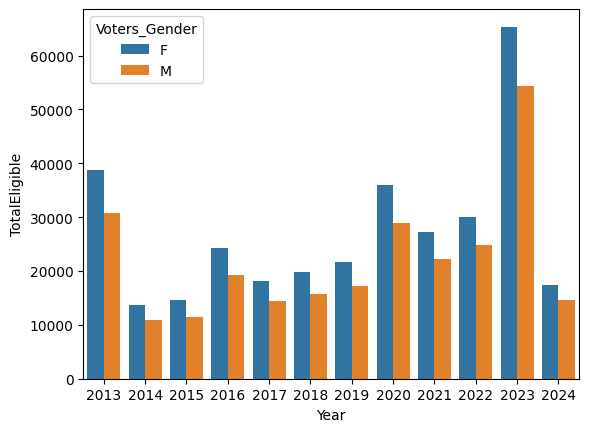

In [109]:
grouped_gender.reset_index(inplace=True)
sns.barplot(grouped_gender, x='Year', y='TotalEligible', hue='Voters_Gender')

In [110]:
long_format_df

,VoterID,ElectionDate,ElectionType,EligibilityStatus,Eligible,Voted,Age_at_Election,Age_Eligible,Registration_Eligible,TurnoutRate,TurnoutPercentage,Voter_Enrollment,Year,Age_Group,Voters_Gender
0,LALMA461833413,2013-04-30,Special,Ineligible_Did_Not_Vote,False,False,19.0,True,False,0.199333,19.93%,Non-Partisan,2013,18-25,F
1,LALMA604158873,2013-04-30,Special,Ineligible_Did_Not_Vote,False,False,16.0,False,False,0.199333,19.93%,Non-Partisan,2013,Under 18,F
2,LALMA410465965,2013-04-30,Special,Ineligible_Did_Not_Vote,False,False,19.0,True,False,0.199333,19.93%,Democratic,2013,18-25,F
3,LALMA162405966,2013-04-30,Special,Eligible_Did_Not_Vote,True,False,66.0,True,True,0.199333,19.93%,Non-Partisan,2013,65-74,M
4,LALMA442082670,2013-04-30,Special,Ineligible_Did_Not_Vote,False,False,62.0,True,False,0.199333,19.93%,Non-Partisan,2013,56-64,M
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
994413,LALMA410155097,2024-03-05,Presidential_Primary,Eligible_Did_Not_Vote,True,False,71.0,True,True,0.228624,22.86%,Democratic,2024,65-74,F
994414,LALMA159543975,2024-03-05,Presidential_Primary,Eligible_Did_Not_Vote,True,False,65.0,True,True,0.228624,22.86%,Republican,2024,65-74,M
994415,LALMA410395894,2024-03-05,Presidential_Primary,Eligible_Did_Not_Vote,True,False,35.0,True,True,0.228624,22.86%,Democratic,2024,26-35,M
994416,LALMA160899592,2024-03-05,Presidential_Primary,Eligible_Did_Not_Vote,True,False,40.0,True,True,0.228624,22.86%,Non-Partisan,2024,36-45,F
